In [6]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import optuna

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, auc, roc_auc_score, precision_recall_curve,
                             average_precision_score)
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_sample_weight

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
print("xgboost", xgb.__version__, "| optuna", optuna.__version__)

xgboost 3.4.1 | optuna 5.0.0


## Part 1 – Cleaned dataset, encoding and target classes 

* `Order`, `PID`: identifiers
* `Alley`, `Pool QC`, `Misc Feature`: > 90 % "NA"
* `Garage Yr Blt`: correlation 0.83 with `Year Built`
* `Garage Cars`: correlation 0.89 with `Garage Area`
* For all other categorical columns "NA" means "feature not present" (no garage, no basement etc) → replaced by the category `"None"`.
* `Lot Frontage` (truly missing, 17 %) → median of the same `Neighborhood`.
* Numeric basement/garage/veneer columns that are NA because the feature does not exist → 0.
* `Gr Liv Area > 4000`: the five outliers from L1 → removed

In [ ]:
initial = pd.read_csv("AmesHousing.csv", sep="\t")
print("Initial shape:", initial.shape)

def clean(df, drop_outliers=True):
    df = df.copy()
    # 1) identifiers and columns that are almost empty
    df = df.drop(columns=["Order", "PID", "Alley", "Pool QC", "Misc Feature",
                          "Garage Yr Blt", "Garage Cars"])
    # 2) outliers identified in L1
    if drop_outliers:
        df = df[df["Gr Liv Area"] <= 4000]
    
    # Missing values
    # 3) "NA" = feature not present -> category "None"
    cat_cols = df.select_dtypes(include="object").columns
    df[cat_cols] = df[cat_cols].fillna("None")
    df["Electrical"] = df["Electrical"].replace("None", df["Electrical"].mode()[0])  # 1 truly missing value
    # 4) numeric columns
    df["Lot Frontage"] = df.groupby("Neighborhood")["Lot Frontage"].transform(lambda s: s.fillna(s.median()))
    df["Lot Frontage"] = df["Lot Frontage"].fillna(df["Lot Frontage"].median())
    num_cols = df.select_dtypes(include="number").columns.drop("SalePrice")
    df[num_cols] = df[num_cols].fillna(0)
    return df

housing = clean(initial)
print("Cleaned shape:", housing.shape, "| remaining NaN:", int(housing.isna().sum().sum()))

Initial shape: (2930, 82)
Cleaned shape: (2925, 75) | remaining NaN: 0


,class,count,percent
0,<100k,237,8.1
1,100-130k,509,17.4
2,130-180k,1036,35.4
3,180-250k,684,23.4
4,250-400k,397,13.6
5,>=400k,62,2.1


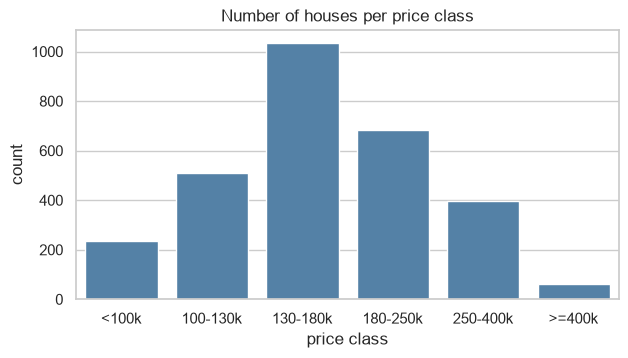

In [8]:
BINS = [0, 100_000, 130_000, 180_000, 250_000, 400_000, np.inf]
CLASS_NAMES = ["<100k", "100-130k", "130-180k", "180-250k", "250-400k", ">=400k"]

def make_target(df):
    # intervals [a, b): 100000 belongs to class 1, 400000 to class 5
    return pd.cut(df["SalePrice"], bins=BINS, right=False, labels=False).astype(int)

y_all = make_target(housing)
dist = pd.DataFrame({"class": CLASS_NAMES, "count": y_all.value_counts().sort_index().values})
dist["percent"] = (dist["count"] / len(y_all) * 100).round(1)
display(dist)

plt.figure(figsize=(7, 3.5))
sns.barplot(x=CLASS_NAMES, y=dist["count"], color="steelblue")
plt.title("Number of houses per price class"); plt.ylabel("count"); plt.xlabel("price class")
plt.show()


**Interpretation.** The classes are imbalanced: the middle class `130-180k` contains about 35 % of the houses, whereas `>=400k` has only 62 houses (2.1 %). This is why *accuracy alone is misleading* (always predicting `130-180k` would give 35 %), why we report **macro-averaged** metrics (every class counts equally), and why stratification and class weights are tested.

In [10]:
QUAL = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
ORDINAL_MAPS = {
    "Exter Qual": QUAL, "Exter Cond": QUAL, "Bsmt Qual": QUAL, "Bsmt Cond": QUAL,
    "Heating QC": QUAL, "Kitchen Qual": QUAL, "Fireplace Qu": QUAL,
    "Garage Qual": QUAL, "Garage Cond": QUAL,
    "Bsmt Exposure": {"None": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4},
    "BsmtFin Type 1": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "BsmtFin Type 2": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "Functional": {"Sal": 1, "Sev": 2, "Maj2": 3, "Maj1": 4, "Mod": 5, "Min2": 6, "Min1": 7, "Typ": 8},
    "Garage Finish": {"None": 0, "Unf": 1, "RFn": 2, "Fin": 3},
    "Paved Drive": {"N": 0, "P": 1, "Y": 2},
    "Fence": {"None": 0, "MnWw": 1, "GdWo": 2, "MnPrv": 3, "GdPrv": 4},
    "Lot Shape": {"IR3": 0, "IR2": 1, "IR1": 2, "Reg": 3},
    "Land Slope": {"Sev": 0, "Mod": 1, "Gtl": 2},
    "Utilities": {"ELO": 0, "NoSeWa": 1, "NoSewr": 2, "AllPub": 3},
    "Central Air": {"N": 0, "Y": 1},
}

def add_features(df):
    # combined features
    d = df.copy()
    d["TotalSF"]      = d["Total Bsmt SF"] + d["1st Flr SF"] + d["2nd Flr SF"]
    d["HouseAge"]     = d["Yr Sold"] - d["Year Built"]
    d["RemodAge"]     = d["Yr Sold"] - d["Year Remod/Add"]
    d["TotalBath"]    = d["Full Bath"] + 0.5 * d["Half Bath"] + d["Bsmt Full Bath"] + 0.5 * d["Bsmt Half Bath"]
    d["TotalPorchSF"] = d["Open Porch SF"] + d["Enclosed Porch"] + d["3Ssn Porch"] + d["Screen Porch"] + d["Wood Deck SF"]
    d["IsRemodeled"]  = (d["Year Remod/Add"] != d["Year Built"]).astype(int)
    d["QualxSF"]      = d["Overall Qual"] * d["Gr Liv Area"]
    return d

def build_features(df, nominal="onehot", engineer=False, drop_corr=False):
    d = df.drop(columns=["SalePrice"]).copy()
    d["MS SubClass"] = d["MS SubClass"].astype(str) 
    if engineer:
        d = add_features(d)
    for col, mp in ORDINAL_MAPS.items():
        d[col] = d[col].map(mp).astype(float)
    nom_cols = d.select_dtypes(include="object").columns.tolist()
    if nominal == "onehot":
        d = pd.get_dummies(d, columns=nom_cols, dtype=int)
    elif nominal == "label":
        for c in nom_cols:
            d[c] = d[c].astype("category").cat.codes
    elif nominal == "native":
        for c in nom_cols:
            d[c] = d[c].astype("category")
    if drop_corr:
        num = d.select_dtypes(include="number")
        corr = num.corr().abs()
        upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
        to_drop = [c for c in upper.columns if (upper[c] > 0.9).any()]
        d = d.drop(columns=to_drop)
    d.columns = [str(c).replace("[", "(").replace("]", ")").replace("<", "lt") for c in d.columns]
    return d

X_all = build_features(housing)
print("Features after encoding:", X_all.shape[1])
print("Nominal columns one-hot encoded:", housing.drop(columns=["SalePrice"]).select_dtypes("object").columns.difference(list(ORDINAL_MAPS)).size + 1)
print("Ordinal columns mapped to integers:", len(ORDINAL_MAPS))
X_all.iloc[:3, :12]

Features after encoding: 236
Nominal columns one-hot encoded: 21
Ordinal columns mapped to integers: 20


,Lot Frontage,Lot Area,Lot Shape,Utilities,Land Slope,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,Exter Qual,Exter Cond
0,141.0,31770,2.0,3.0,2.0,6,5,1960,1960,112.0,3.0,3.0
1,80.0,11622,3.0,3.0,2.0,5,6,1961,1961,0.0,3.0,3.0
2,81.0,14267,2.0,3.0,2.0,6,6,1958,1958,108.0,3.0,3.0


In [ ]:
# base settings of the model(200 succesive decision trees etc)
BASE_PARAMS = dict(n_estimators=200, learning_rate=0.1, max_depth=4, subsample=0.8,
                   colsample_bytree=0.8, min_child_weight=1, gamma=0, reg_lambda=1,
                   tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE)

def fit_model(params, X, y, weights=None, **kw):
    m = xgb.XGBClassifier(**params, **kw)
    m.fit(X, y, sample_weight=weights)
    return m

def scores(y_true, y_pred):
    return dict(accuracy=accuracy_score(y_true, y_pred),
                precision=precision_score(y_true, y_pred, average="macro", zero_division=0),
                recall=recall_score(y_true, y_pred, average="macro", zero_division=0),
                macro_f1=f1_score(y_true, y_pred, average="macro", zero_division=0))

#K-Fold-Cross-Validation
def cv_eval(X, y, params=BASE_PARAMS, splitter=None, weight_mode=None, return_folds=False):
    splitter = splitter or StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
    rows = []
    for tr, va in splitter.split(X, y):
        w = compute_sample_weight(weight_mode, y.iloc[tr]) if weight_mode == "balanced" else None
        if weight_mode == "sqrt":
            w = np.sqrt(compute_sample_weight("balanced", y.iloc[tr]))
        m = fit_model(params, X.iloc[tr], y.iloc[tr], w, **({"enable_categorical": True}
                      if any(str(t) == "category" for t in X.dtypes) else {}))
        r_va = scores(y.iloc[va], m.predict(X.iloc[va]))
        r_tr = scores(y.iloc[tr], m.predict(X.iloc[tr]))
        rows.append({**{f"val_{k}": v for k, v in r_va.items()}, "train_macro_f1": r_tr["macro_f1"],
                     "train_accuracy": r_tr["accuracy"]})
    df = pd.DataFrame(rows)
    return df if return_folds else df.agg(["mean", "std"]).T

def pm(series_mean, series_std, nd=3):
    return f"{series_mean:.{nd}f} ± {series_std:.{nd}f}"

## Part 2 – Train/test split 10 % vs 20 %, with and without stratification

acc_mean  acc_std  f1_mean  f1_std  train_f1  class5_in_test_min  class5_in_test_max
test_size stratified                                                                                      
10 %      False         0.7713   0.0169   0.7596  0.0169    0.9932                   2                  11
          True          0.7706   0.0298   0.7558  0.0525    0.9942                   6                   6
20 %      False         0.7631   0.0218   0.7416  0.0175    0.9951                   7                  16
          True          0.7754   0.0140   0.7625  0.0255    0.9954                  12                  12

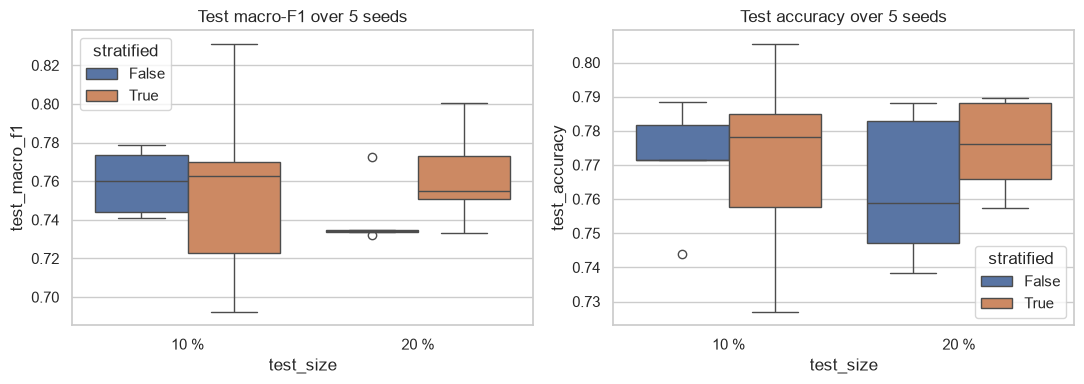

In [12]:
rows = []
for test_size in [0.10, 0.20]:
    for strat in [False, True]:
        for seed in range(5):
            Xtr, Xte, ytr, yte = train_test_split(X_all, y_all, test_size=test_size, random_state=seed,
                                                  stratify=y_all if strat else None)
            m = fit_model(BASE_PARAMS, Xtr, ytr)
            te, tr = scores(yte, m.predict(Xte)), scores(ytr, m.predict(Xtr))
            rows.append(dict(test_size=f"{int(test_size*100)} %", stratified=strat, seed=seed,
                             test_accuracy=te["accuracy"], test_macro_f1=te["macro_f1"],
                             train_macro_f1=tr["macro_f1"], n_test=len(yte),
                             test_n_class5=int((yte == 5).sum())))
split_res = pd.DataFrame(rows)
summary = split_res.groupby(["test_size", "stratified"]).agg(
    acc_mean=("test_accuracy", "mean"), acc_std=("test_accuracy", "std"),
    f1_mean=("test_macro_f1", "mean"), f1_std=("test_macro_f1", "std"),
    train_f1=("train_macro_f1", "mean"),
    class5_in_test_min=("test_n_class5", "min"), class5_in_test_max=("test_n_class5", "max")).round(4)
display(summary)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=split_res, x="test_size", y="test_macro_f1", hue="stratified", ax=ax[0])
ax[0].set_title("Test macro-F1 over 5 seeds")
sns.boxplot(data=split_res, x="test_size", y="test_accuracy", hue="stratified", ax=ax[1])
ax[1].set_title("Test accuracy over 5 seeds")
plt.tight_layout(); plt.show()

* **Overall Performance**: All four configurations reach a very similar test performance (macro-F1 ≈ 0.75–0.76, accuracy ≈ 0.77–0.78).
* **The Role of Stratification**: Stratification makes our test set stable and consistent. With stratification, the rare >=400k class always shows up the exact same number of times—6 times for a 10% test or 12 times for a 20% test. Without it, the count bounces around randomly between 2 and 11 (for 10%) or 7 and 16 (for 20%). If the test randomly gets only 2 rare houses, the score for that class becomes pretty much useless. The highest average macro-F1 was achieved using the 20% stratified setup (0.760). 
* **10% vs. 20% Test**: A 10% test set (≈ 293 houses) leaves more data for training (less bias), but the estimate is noisier (e.g., std of macro-F1 is 0.052 with stratification, with only 6 rare houses in the test set). A 20% test set gives a more reliable estimate and costs only a little training data.
* **Overfitting Issue**: The training macro-F1 is ≈ 0.99 while the test macro-F1 is ≈ 0.75: the model fits the training data almost perfectly 

## Part 3 – k-fold cross validation (k = 5 and k = 10), bias–variance trade-off

,k,splitter,val_accuracy,val_macro_f1,train_macro_f1,gap_train_minus_val,f1_range_over_folds
0,5,KFold,0.757 ± 0.020,0.746 ± 0.014,0.995,0.250,0.734 – 0.762
1,5,StratifiedKFold,0.769 ± 0.016,0.742 ± 0.025,0.995,0.253,0.711 – 0.779
2,10,KFold,0.766 ± 0.021,0.756 ± 0.016,0.993,0.237,0.730 – 0.781
3,10,StratifiedKFold,0.772 ± 0.028,0.755 ± 0.035,0.993,0.238,0.691 – 0.803


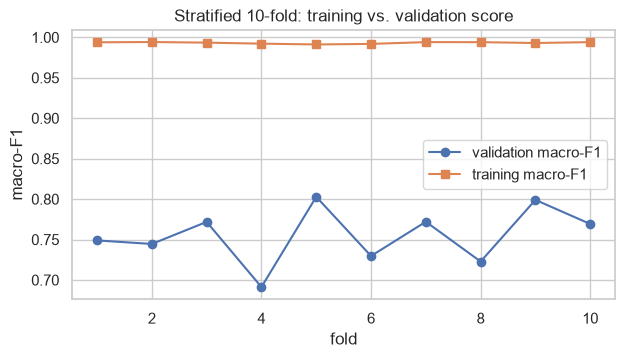

In [13]:
rows = []
for k in [5, 10]:
    for name, SplitCls in [("KFold", KFold), ("StratifiedKFold", StratifiedKFold)]:
        folds = cv_eval(X_all, y_all, BASE_PARAMS, SplitCls(k, shuffle=True, random_state=RANDOM_STATE), return_folds=True)
        rows.append(dict(k=k, splitter=name,
                         val_accuracy=pm(folds.val_accuracy.mean(), folds.val_accuracy.std()),
                         val_macro_f1=pm(folds.val_macro_f1.mean(), folds.val_macro_f1.std()),
                         train_macro_f1=round(folds.train_macro_f1.mean(), 3),
                         gap_train_minus_val=round(folds.train_macro_f1.mean() - folds.val_macro_f1.mean(), 3),
                         f1_range_over_folds=f"{folds.val_macro_f1.min():.3f} – {folds.val_macro_f1.max():.3f}"))
        if k == 10 and name == "StratifiedKFold":
            fold_plot = folds
cv_table = pd.DataFrame(rows)
display(cv_table)

plt.figure(figsize=(7, 3.5))
plt.plot(range(1, 11), fold_plot.val_macro_f1, "o-", label="validation macro-F1")
plt.plot(range(1, 11), fold_plot.train_macro_f1, "s-", label="training macro-F1")
plt.xlabel("fold"); plt.ylabel("macro-F1"); plt.title("Stratified 10-fold: training vs. validation score")
plt.legend(); plt.show()

* **Cross-Validation**: Instead of doing just one random split, cross-validation tests every house on validation once. This gives us a much more reliable average and standard deviation. Our validation macro-F1 ends up around 0.74–0.76, which matches what we saw in the previous split experiments.   
* **k = 5 vs. k = 10**: When we use $k = 10$, the model trains on 90% of the data instead of 80%, so the score is slightly higher and less pessimistic (lower bias). However, because each validation chunk is smaller (~293 houses with only about 6 rare houses), the scores bounce around a lot more between folds (ranging from 0.6961 to 0.803), meaning higher variance. Plus, $k = 10$ takes twice as long to compute.   
* **KFold vs. StratifiedKFold**: The average scores are pretty much the same (within one standard deviation). Still, stratification is the safer and better choice because it makes sure the rare class is always properly balanced in every fold.   
* **Bias-Variance Trade-off**: There is a huge gap here—our training macro-F1 is around 0.99, while validation drops to about 0.75. This means the model has very low bias but high variance, basically memorizing the training data instead of generalizing (overfitting). To fix this, we'd normally need more data, stronger regularization, or simpler trees (which we'll test in Part 7).

**Fixed split strategy**: From now on, we stick to a single, fixed 80% / 20% stratified split so that the test set remains completely untouched until the final evaluation. All model tuning, hyperparameter choices, and Optuna searches will be done exclusively using 5-fold stratified cross-validation on the training portion only, keeping our test results completely honest and unbiased.

In [14]:
idx_train, idx_test = train_test_split(housing.index, test_size=0.20, random_state=RANDOM_STATE,
                                       stratify=y_all)
y_train, y_test = y_all.loc[idx_train], y_all.loc[idx_test]
X_train, X_test = X_all.loc[idx_train], X_all.loc[idx_test]
print("train:", X_train.shape, "| test:", X_test.shape)
print(pd.DataFrame({"train %": (y_train.value_counts(normalize=True).sort_index()*100).round(1),
                    "test %": (y_test.value_counts(normalize=True).sort_index()*100).round(1)}))

train: (2340, 236) | test: (585, 236)
           train %  test %
SalePrice                 
0              8.1     8.2
1             17.4    17.4
2             35.4    35.4
3             23.4    23.4
4             13.6    13.5
5              2.1     2.1
